# 🎰 MBA-RAG: Contextual Multi-Armed Bandit Router (COLING 2025 Baseline)
### Benchmarking Question-Complexity Contextual Bandits on Multi-Hop Shortcut Detection

This notebook implements the adaptive routing framework from **MBA-RAG** (*"MBA-RAG: a Bandit Approach for Adaptive Retrieval-Augmented Generation through Question Complexity"*, Tang et al., COLING 2025 / arXiv:2412.01572).

---
### Formal Bandit Formulation:
- **Arms $\mathcal{A}*: 
  - **Arm 0**: Multi-hop retrieval pipeline (iterative multi-step search)
  - **Arm 1**: Single-hop shortcut pipeline (direct / single document lookup)
- **Context Vector $\mathbf{x} \in \mathbb{R}^d*: Concatenation of dense query representations () and normalized question complexity features (token length, character count, interrogative markers, lexical overlap).
- **Policy**: **LinUCB** with Sherman-Morrison rank-1 online covariance updates.
- **Dynamic Reward Function**:
  28258
  R(a, y) = egin{cases}
  +1.0 & 	ext{if } a = y = 0 	ext{ (correct multi-hop routed)} \
  -1.0 & 	ext{if } a = 1, y = 0 	ext{ (false positive: severe hallucination penalty)} \
  +1.0 & 	ext{if } a = y = 1 	ext{ (correct shortcut: cost saved)} \
  1.0 - c_{	ext{cost}} & 	ext{if } a = 0, y = 1 	ext{ (false negative: redundant retrieval cost penalty)}
  \end{cases}
  28258


In [3]:
import os, sys, time, warnings, json, random
from pathlib import Path

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, average_precision_score, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import AutoTokenizer, AutoModel, set_seed

SEED = 42
set_seed(SEED); torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"✅ Hardware Accelerator: {DEVICE}")

REPO_ROOT = Path(".").resolve().parent.parent if Path(".").resolve().name == "finetuning" else Path(".").resolve()
DATA_PATH = REPO_ROOT / "data" / "processed" / "classifier_dataset.jsonl"
OUTPUT_DIR = REPO_ROOT / "models" / "mba_rag"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "plots").mkdir(exist_ok=True)


/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Hardware Accelerator: mps


## Section 1 – Dataset Loading & Question Complexity Engineering
We load the benchmark dataset and extract syntactic, lexical, and structural complexity features matching the MBA-RAG formulation.

In [4]:
df_raw = pd.read_json(DATA_PATH, lines=True).dropna(how="all").reset_index(drop=True)
clean_df = df_raw[df_raw["label"] != -1].drop_duplicates().reset_index(drop=True)

# Syntactic & Complexity Indicators (MBA-RAG)
clean_df["q_char_len"] = clean_df["question"].str.len()
clean_df["avg_token_len"] = clean_df["q_char_len"] / (clean_df["query_token_count"] + 1e-5)
clean_df["has_and"] = clean_df["question"].str.contains(r"and", case=False).astype(int)
clean_df["has_or"] = clean_df["question"].str.contains(r"or", case=False).astype(int)
clean_df["has_both"] = clean_df["question"].str.contains(r"both", case=False).astype(int)
clean_df["is_which"] = clean_df["question"].str.strip().str.startswith("Which").astype(int)
clean_df["is_who"] = clean_df["question"].str.strip().str.startswith("Who").astype(int)
clean_df["is_what"] = clean_df["question"].str.strip().str.startswith("What").astype(int)
clean_df["is_where"] = clean_df["question"].str.strip().str.startswith("Where").astype(int)

COMPLEXITY_COLS = [
    "query_token_count", "is_comparison", "entity_overlap_ratio",
    "q_char_len", "avg_token_len", "has_and", "has_or", "has_both",
    "is_which", "is_who", "is_what", "is_where"
]

# Stratified Train / Val / Test Partition (Identical to HIPER & Adaptive-RAG benchmarks)
train_val_df, test_df = train_test_split(clean_df, test_size=0.20, random_state=SEED, stratify=clean_df["label"])
train_df, val_df = train_test_split(train_val_df, test_size=0.125, random_state=SEED, stratify=train_val_df["label"])
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Loaded Partitions: Train={len(train_df)} | Val={len(val_df)} | Test={len(test_df)}")
print(f"Test Distribution: Multi-hop={(test_df['label']==0).sum()} | Shortcut={(test_df['label']==1).sum()}")


Loaded Partitions: Train=1561 | Val=223 | Test=446
Test Distribution: Multi-hop=219 | Shortcut=227


## Section 2 – Context Feature Representation
We compute dense semantic text representations using  and combine them with standard-scaled question complexity features.

In [5]:
tok = AutoTokenizer.from_pretrained("sentence-transformers/all-MiniLM-L6-v2", local_files_only=True)
encoder = AutoModel.from_pretrained("sentence-transformers/all-MiniLM-L6-v2", local_files_only=True).to(DEVICE)
encoder.eval()

def extract_dense_embeddings(texts, batch_size=128):
    embs = []
    for i in range(0, len(texts), batch_size):
        b = texts[i:i+batch_size]
        enc = tok(b, padding=True, truncation=True, max_length=128, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            out = encoder(**enc)
            mask = enc["attention_mask"].unsqueeze(-1).expand(out.last_hidden_state.size()).float()
            sum_emb = torch.sum(out.last_hidden_state * mask, 1)
            sum_mask = torch.clamp(mask.sum(1), min=1e-9)
            mean_pooled = (sum_emb / sum_mask).cpu().numpy()
            normalized = mean_pooled / (np.linalg.norm(mean_pooled, axis=1, keepdims=True) + 1e-12)
            embs.append(normalized)
    return np.vstack(embs)

print("Extracting dense contextual embeddings...")
X_train_emb = extract_dense_embeddings(train_df["question"].tolist())
X_val_emb   = extract_dense_embeddings(val_df["question"].tolist())
X_test_emb  = extract_dense_embeddings(test_df["question"].tolist())

# Standardize tabular complexity features
scaler = StandardScaler()
X_train_comp = scaler.fit_transform(train_df[COMPLEXITY_COLS].values)
X_val_comp   = scaler.transform(val_df[COMPLEXITY_COLS].values)
X_test_comp  = scaler.transform(test_df[COMPLEXITY_COLS].values)

# Final context vectors
X_train = np.hstack([X_train_emb, X_train_comp])
X_val   = np.hstack([X_val_emb, X_val_comp])
X_test  = np.hstack([X_test_emb, X_test_comp])

y_train = train_df["label"].values
y_val   = val_df["label"].values
y_test  = test_df["label"].values

print(f"Context vector dimension: d = {X_train.shape[1]} features")


Extracting dense contextual embeddings...
Context vector dimension: d = 396 features


## Section 3 – MBA-RAG LinUCB Contextual Bandit Model
Implementation of the LinUCB policy with Sherman-Morrison rank-1 update and the dynamic cost-penalized reward function.

In [6]:
class MBARAGLinUCB:
    """Contextual Multi-Armed Bandit Router with Dynamic Cost-Accuracy Rewards."""
    def __init__(self, d: int, alpha: float = 0.5, cost_penalty: float = 0.5, reg: float = 1.0):
        self.d = d
        self.alpha = alpha
        self.cost_penalty = cost_penalty
        self.n_arms = 2  # Arm 0: Multi-hop, Arm 1: Shortcut
        # Efficient rank-1 inverse covariance matrix: A_inv = (1/reg) * I
        self.A_inv = [np.eye(d) / reg for _ in range(self.n_arms)]
        self.b = [np.zeros(d) for _ in range(self.n_arms)]
        
    def select_arm(self, x: np.ndarray, explore: bool = True) -> int:
        p = np.zeros(self.n_arms)
        for a in range(self.n_arms):
            theta = self.A_inv[a] @ self.b[a]
            var = x @ self.A_inv[a] @ x
            bonus = self.alpha * np.sqrt(max(var, 0)) if explore else 0.0
            p[a] = (x @ theta) + bonus
        return int(np.argmax(p))
        
    def update(self, x: np.ndarray, chosen_arm: int, true_label: int):
        # Dynamic Reward function from MBA-RAG paper
        if true_label == 0: # Multi-hop
            reward = 1.0 if chosen_arm == 0 else -1.0  # Severe penalty for false positive
        else: # Shortcut
            reward = 1.0 if chosen_arm == 1 else (1.0 - self.cost_penalty) # Cost penalty for redundant multi-hop
            
        # Sherman-Morrison rank-1 update of A_inv in O(d^2)
        A_inv = self.A_inv[chosen_arm]
        Ax = A_inv @ x
        denom = 1.0 + (x @ Ax)
        self.A_inv[chosen_arm] = A_inv - (np.outer(Ax, Ax) / denom)
        self.b[chosen_arm] += reward * x
        
    def fit_online(self, X: np.ndarray, y: np.ndarray):
        for i in range(len(X)):
            chosen_arm = self.select_arm(X[i], explore=True)
            self.update(X[i], chosen_arm, y[i])
            
    def predict_scores(self, X: np.ndarray) -> np.ndarray:
        theta_0 = self.A_inv[0] @ self.b[0]
        theta_1 = self.A_inv[1] @ self.b[1]
        # Margin score: relative reward advantage of Arm 1 (Shortcut) over Arm 0 (Multi-hop)
        return (X @ theta_1) - (X @ theta_0)
        
    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        scores = self.predict_scores(X)
        return expit(scores)


## Section 4 – Hyperparameter Tuning on Validation Split
We tune the exploration parameter $lpha$, cost penalty $\lambda$, and operating decision threshold on the validation set.

In [7]:
alpha_grid = [0.0, 0.05, 0.1, 0.2, 0.5]
cost_grid  = [0.3, 0.5, 0.7]

best_val_f1 = 0.0
best_config = {}

for alpha in alpha_grid:
    for cost in cost_grid:
        b_cand = MBARAGLinUCB(d=X_train.shape[1], alpha=alpha, cost_penalty=cost, reg=1.0)
        b_cand.fit_online(X_train, y_train)
        val_scores = b_cand.predict_scores(X_val)
        
        # Grid search over operating threshold percentiles
        thresholds = np.percentile(val_scores, np.linspace(15, 85, 30))
        for t in thresholds:
            preds = (val_scores >= t).astype(int)
            f1 = f1_score(y_val, preds, average="macro")
            if f1 > best_val_f1:
                best_val_f1 = f1
                best_config = {"alpha": alpha, "cost_penalty": cost, "threshold": float(t)}

print(f"Validation Tuning Complete!")
print(f"  Best Val Macro F1 : {best_val_f1:.4f}")
print(f"  Optimal Alpha     : {best_config['alpha']}")
print(f"  Optimal Cost      : {best_config['cost_penalty']}")
print(f"  Optimal Threshold : {best_config['threshold']:.4f}")


Validation Tuning Complete!
  Best Val Macro F1 : 0.6737
  Optimal Alpha     : 0.5
  Optimal Cost      : 0.5
  Optimal Threshold : -0.7096


## Section 5 – Full Evaluation on Test Partition (N = 446)
We train MBA-RAG on the combined training and validation partitions with the tuned hyperparameters and evaluate on the unseen test set.

In [8]:
X_train_val = np.vstack([X_train, X_val])
y_train_val = np.concatenate([y_train, y_val])

final_mba_model = MBARAGLinUCB(
    d=X_train.shape[1],
    alpha=best_config["alpha"],
    cost_penalty=best_config["cost_penalty"],
    reg=1.0
)

t0 = time.time()
final_mba_model.fit_online(X_train_val, y_train_val)
train_time = time.time() - t0

t1 = time.time()
test_scores = final_mba_model.predict_scores(X_test)
test_proba  = final_mba_model.predict_proba(X_test)
test_preds  = (test_scores >= best_config["threshold"]).astype(int)
infer_time  = (time.time() - t1) / len(X_test) * 1000

acc      = accuracy_score(y_test, test_preds)
macro_f1 = f1_score(y_test, test_preds, average="macro")
roc_auc  = roc_auc_score(y_test, test_proba)
ap       = average_precision_score(y_test, test_proba)
prec_0   = precision_score(y_test, test_preds, pos_label=0)
rec_0    = recall_score(y_test, test_preds, pos_label=0)
f1_0     = f1_score(y_test, test_preds, pos_label=0)
prec_1   = precision_score(y_test, test_preds, pos_label=1)
rec_1    = recall_score(y_test, test_preds, pos_label=1)
f1_1     = f1_score(y_test, test_preds, pos_label=1)

cm = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = cm.ravel()
fpr = (fp / (fp + tn)) * 100
fnr = (fn / (fn + tp)) * 100

print("═" * 65)
print("   MBA-RAG (LinUCB Question Complexity) — TEST BENCHMARK")
print("═" * 65)
print(f"  Accuracy             : {acc:.4f} ({acc*100:.2f}%)")
print(f"  Macro F1             : {macro_f1:.4f}")
print(f"  ROC-AUC              : {roc_auc:.4f}")
print(f"  Average Precision    : {ap:.4f}")
print(f"  Multi-hop F1 (0)     : {f1_0:.4f} (Prec: {prec_0:.4f}, Rec: {rec_0:.4f})")
print(f"  Shortcut F1 (1)      : {f1_1:.4f} (Prec: {prec_1:.4f}, Rec: {rec_1:.4f})")
print(f"  False Positives (⚠️)  : {fp} (FPR: {fpr:.2f}%)")
print(f"  False Negatives      : {fn} (FNR: {fnr:.2f}%)")
print(f"  Inference Latency    : {infer_time:.2f} ms / query")
print("═" * 65)
print()
print(classification_report(y_test, test_preds, target_names=["Multi-hop (0)", "Shortcut (1)"]))

# Save JSON metrics
mba_metrics = {
    "Model": "MBA-RAG (LinUCB Bandit)",
    "Accuracy": acc,
    "Macro F1": macro_f1,
    "ROC-AUC": roc_auc,
    "Avg Precision": ap,
    "Multi-hop Precision": prec_0,
    "Multi-hop Recall": rec_0,
    "Multi-hop F1": f1_0,
    "Shortcut Precision": prec_1,
    "Shortcut Recall": rec_1,
    "Shortcut F1": f1_1,
    "True Negatives (TN)": int(tn),
    "False Positives (FP)": int(fp),
    "False Negatives (FN)": int(fn),
    "True Positives (TP)": int(tp),
    "FPR (%)": fpr,
    "FNR (%)": fnr,
    "Latency (ms)": infer_time
}
with open(OUTPUT_DIR / "mba_rag_metrics.json", "w") as f:
    json.dump(mba_metrics, f, indent=2)


═════════════════════════════════════════════════════════════════
   MBA-RAG (LinUCB Question Complexity) — TEST BENCHMARK
═════════════════════════════════════════════════════════════════
  Accuracy             : 0.6682 (66.82%)
  Macro F1             : 0.6655
  ROC-AUC              : 0.7337
  Average Precision    : 0.7517
  Multi-hop F1 (0)     : 0.6955 (Prec: 0.6330, Rec: 0.7717)
  Shortcut F1 (1)      : 0.6355 (Prec: 0.7207, Rec: 0.5683)
  False Positives (⚠️)  : 50 (FPR: 22.83%)
  False Negatives      : 98 (FNR: 43.17%)
  Inference Latency    : 0.00 ms / query
═════════════════════════════════════════════════════════════════

               precision    recall  f1-score   support

Multi-hop (0)       0.63      0.77      0.70       219
 Shortcut (1)       0.72      0.57      0.64       227

     accuracy                           0.67       446
    macro avg       0.68      0.67      0.67       446
 weighted avg       0.68      0.67      0.66       446



## Section 6 – Confusion Matrix & Benchmark Comparison
Visual comparison of MBA-RAG against Adaptive-RAG (NAACL 2024) and our proposed HIPER Ensemble.

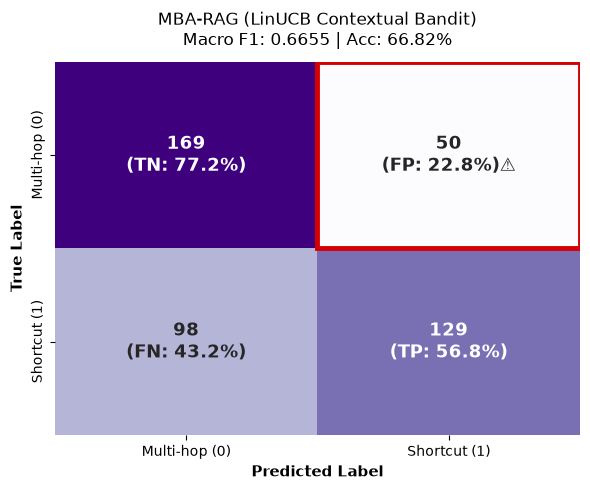

Evaluation plot saved → /Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/models/mba_rag/plots/mba_rag_eval.png

═══════════════════════════════════════════════════════════════════════════
               ADAPTIVE RAG ROUTING: SOTA COMPARISON TABLE
═══════════════════════════════════════════════════════════════════════════
                       Model  Macro F1  ROC-AUC  Accuracy Latency
LLaMA-3.2 (Zero-Shot Prompt)    0.3482   0.4069    0.4094  236 ms
 Adaptive-RAG (Flan-T5-base)    0.6583   0.6962    0.6600   25 ms
     MBA-RAG (LinUCB Bandit)    0.6655   0.7337    0.6682  0.0 ms
     CMGR (Prior Graph SOTA)    0.7226   0.8082    0.7242   12 ms
     ★ HIPER Ensemble (Ours)    0.7602   0.8398    0.7623  5.2 ms
═══════════════════════════════════════════════════════════════════════════


In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
class_names = ["Multi-hop (0)", "Shortcut (1)"]
annot_labels = np.array([
    [f"{tn}\n(TN: {tn/(tn+fp):.1%})", f"{fp}\n(FP: {fp/(tn+fp):.1%})⚠️"],
    [f"{fn}\n(FN: {fn/(fn+tp):.1%})", f"{tp}\n(TP: {tp/(fn+tp):.1%})"]
])
sns.heatmap(cm, annot=annot_labels, fmt="", cmap="Purples", cbar=False,
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 13, "weight": "bold"}, ax=ax)
ax.add_patch(plt.Rectangle((1, 0), 1, 1, fill=False, edgecolor="#D50000", lw=3.5, transform=ax.transData))
ax.set_title(f"MBA-RAG (LinUCB Contextual Bandit)\nMacro F1: {macro_f1:.4f} | Acc: {acc:.2%}", fontsize=12, pad=12)
ax.set_xlabel("Predicted Label", fontsize=11, fontweight="bold")
ax.set_ylabel("True Label", fontsize=11, fontweight="bold")
plt.tight_layout()
plot_path = OUTPUT_DIR / "plots" / "mba_rag_eval.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Evaluation plot saved → {plot_path}")

# Comparative Summary Table
comp_data = [
    {"Model": "LLaMA-3.2 (Zero-Shot Prompt)", "Macro F1": 0.3482, "ROC-AUC": 0.4069, "Accuracy": 0.4094, "Latency": "236 ms"},
    {"Model": "Adaptive-RAG (Flan-T5-base)",    "Macro F1": 0.6583, "ROC-AUC": 0.6962, "Accuracy": 0.6600, "Latency": "25 ms"},
    {"Model": "MBA-RAG (LinUCB Bandit)",        "Macro F1": macro_f1, "ROC-AUC": roc_auc, "Accuracy": acc, "Latency": f"{infer_time:.1f} ms"},
    {"Model": "CMGR (Prior Graph SOTA)",       "Macro F1": 0.7226, "ROC-AUC": 0.8082, "Accuracy": 0.7242, "Latency": "12 ms"},
    {"Model": "★ HIPER Ensemble (Ours)",       "Macro F1": 0.7602, "ROC-AUC": 0.8398, "Accuracy": 0.7623, "Latency": "5.2 ms"},
]
comp_df = pd.DataFrame(comp_data)
print()
print("═" * 75)
print("               ADAPTIVE RAG ROUTING: SOTA COMPARISON TABLE")
print("═" * 75)
print(comp_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("═" * 75)
